# 🇩🇿 NLP Practical Work — Synthetic corpus & classification in Darija
**Group 2 · NLP, Dialects & Disinformation**
Kadouria Youcef · Atia Nour · Islam Cherif El Khir

This notebook contains **the whole project in a single file**, with a comment on every line of code.

## The project in 3 sentences
1. **NLG (generation)**: an LLM wrote a corpus of Darija sentences (with French/Arabic code-switching and arabizi), each with an intended label (positive / negative / neutral, or fake / real).
2. **NLU (understanding)**: a classifier tries to recover the label of each sentence.
3. **Evaluation**: we compare the predictions with the labels, on the generated corpus **and** on reference sentences (the "gold").

## How to use this notebook
- Run the cells **in order**, from top to bottom (`Shift + Enter` runs one cell).
- **No LLM, no API key and no internet are needed.** A Darija corpus **written by an LLM (Claude)** is provided in `data/corpus_llm_sentiment.csv` and `data/corpus_llm_disinfo.csv`.
- All settings you may want to change are in **section 2**.
- The numbers in the presentation come from this notebook (section 11 updates them automatically).

## Outline
| # | Section | Purpose |
|---|---|---|
| 1 | Imports | Load the libraries |
| 2 | Configuration | Choose the task and the corpus source |
| 3 | Gold data | The reference sentences (the "gold") |
| 4 | NLG | The synthetic corpus (written by an LLM) + a template generator for comparison |
| 5 | NLU | The classifier |
| 6 | Evaluation | Metrics, cross-validation, confusion matrix |
| 7 | Full pipeline | Corpus → classify → evaluate → save |
| 8 | **Usefulness of the synthetic corpus** | *The key experiment*: does the corpus really help? |
| 9 | Disinformation | The same thing for fake / real |
| 10 | Try your own sentence | Your own sentence |
| 11 | Update the presentation | Writes the numbers into `presentation/index.html` |
| 12 | Glossary & limits | The words to know |

> Convention: the sentence lists in section 3 are **data**; the comments explain every line of **code**.

## 1. Imports

In [1]:
import json                                 # json: read and write the JSON format (result files)
import re                                   # re: regular expressions, used to detect alphabets (Arabic / Latin) in a sentence
import random                               # random: random draws (used by the template generator)
from pathlib import Path                    # Path: handle file paths, works on Windows and Linux
import pandas as pd                         # pandas: data tables called "DataFrames" (like Excel, but in code)
import matplotlib.pyplot as plt             # matplotlib: draw charts
from sklearn.feature_extraction.text import TfidfVectorizer   # turns text into numbers (TF-IDF)
from sklearn.linear_model import LogisticRegression           # the classification model (logistic regression)
from sklearn.pipeline import make_pipeline                    # chains several steps into a single object
from sklearn.model_selection import StratifiedKFold           # splits data into "folds" keeping class proportions (cross-validation)
from sklearn.metrics import accuracy_score, f1_score          # the two main metrics
from sklearn.metrics import classification_report, confusion_matrix   # detailed report + confusion matrix

print("Imports OK ✅")                       # confirmation message shown under the cell

Imports OK ✅


## 2. Configuration
**This is the only section you need to edit to change the notebook's behaviour.**

| Setting | Possible values | Meaning |
|---|---|---|
| `TASK` | `"sentiment"`, `"disinfo"` | Which task to run |
| `GEN_MODE` | `"file"`, `"offline"` | Corpus written by an LLM, read from `data/` · template corpus (for comparison) |
| `N_PER_LABEL` | an integer | Sentences **per class** for `offline` (ignored with `file`) |
| `RANDOM_SEED` | an integer | Random seed: same seed = same results |

In [2]:
TASK = "sentiment"                          # task: "sentiment" (3 classes) or "disinfo" (fake / real)
GEN_MODE = "file"                           # corpus: "file" (written by an LLM, provided in data/) | "offline" (templates, for comparison)
N_PER_LABEL = 20                            # number of sentences to build for each class (offline mode only)
RANDOM_SEED = 42                            # random seed: same seed = same results at every run

BASE_DIR = Path.cwd()                       # current folder = project folder (the one containing the notebook)
DATA_DIR = BASE_DIR / "data"                # sub-folder where the corpora (CSV) are read / saved
RESULTS_DIR = BASE_DIR / "results"          # sub-folder where metrics (JSON) and images (PNG) are saved
DATA_DIR.mkdir(exist_ok=True)               # create the data folder if it does not exist yet
RESULTS_DIR.mkdir(exist_ok=True)            # create the results folder if it does not exist yet

print(f"Task={TASK} | corpus={GEN_MODE} | n/class={N_PER_LABEL}")   # summary of the settings

Task=sentiment | corpus=file | n/class=20


## 3. "Gold" data: the reference sentences
These sentences are used for **two things**:
1. **few-shot examples**: they appear in the prompt that was used to make the LLM write the corpus (see `build_prompt`, section 4);
2. **reference**: we measure whether the classifier recovers these labels.

⚠️ **To do as a team before the presentation**: these 48 sentences (sentiment) and 20 sentences (disinformation) were **drafted with the help of an LLM** and must be **reviewed and corrected by you, native speakers** (is the label right? is the sentence natural?). This human review is what makes them a real "gold". You can edit `SEEDS` below directly; section 4 checks that no gold sentence is in the corpus.

Each sentence mixes Arabic script, *arabizi* (Latin letters + digits: `3`=ع, `7`=ح, `9`=ق, `5`=خ) and French.

In [3]:
LABELS = {                                          # dictionary: task -> list of possible labels
    "sentiment": ["positive", "negative", "neutral"],   # 3 sentiment classes
    "disinfo": ["fake", "real"],                        # 2 disinformation classes
}

SEEDS = {                                           # dictionary of dictionaries: task -> label -> sentences
    "sentiment": {                                  # ---- sentiment task ----
        "positive": [                               # 16 POSITIVE sentences (satisfaction, joy, praise)
            "والله الماكلة بنينة بزاف، نرجعلكم مرة أخرى إن شاء الله",
            "التوصيل وصل قبل الوقت، service top ماشاء الله",
            "هذا أحسن تلفون شريتو في حياتي، الكاميرا تحفة",
            "الأستاذ يشرح مليح، فهمت الدرس كامل",
            "Franchement l'équipe très gentille، ربي يحفظهم",
            "تبارك الله على الجو في بجاية، منظر يهبل",
            "wallah le film كان روعة, nhabou bzaf",
            "Merci bzaf, kolchi kan mrigl w l'accueil ndif",
            "rani farhan bzaf, rbaht el concours",
            "had l'application mli7a bzaf, sahla w sari3a",
            "le prix معقول و la qualité ممتازة",
            "ماتش اليوم كان عسل، الخضر لعبو مليح",
            "الطبيب مليح بزاف وسمعني مليح، الله يعطيه الصحة",
            "nhabha had la chanson, ki nsmaha nfrah",
            "كامل راضيين على التربص، l'organisation كانت نيكل",
            "الحمد لله نجحت في الباك، فرحة ما تتوصفش",
        ],
        "negative": [                               # 16 NEGATIVE sentences (anger, disappointment, complaint)
            "الخدمة زبل، استنيت ساعتين وما جاوبوني",
            "Franchement nul، le colis وصلني مكسر",
            "ما عجبنيش الطبخ، بارد وما فيه ذوق",
            "wallah ma3jabnich had le service, makach respect",
            "l'application تبلوكا كل مرة، ما تخدمش",
            "الأسعار نارية و la qualité ما تسواش",
            "rani zaafen bzaf, tbahdlt 3la rassi",
            "الطريق مليانة حفر والدولة ما دايرة والو",
            "bezzaf ghla, w la qualité wa3ra",
            "الأنترنت ضعيفة هذي كاش أسبوع، vraiment décevant",
            "le médecin ما سمعنيش، خلاني نستنى بزاف",
            "ماتش خايب، الحكم باع الماتش",
            "j'ai perdu mon temps، فيلم ممل بزاف",
            "تعبت من الزحمة والطوابير في البريد",
            "makanch l'eau 3 jours, c'est inadmissible",
            "السرفيس واعر، ما نرجعش ليهم أبدا",
        ],
        "neutral": [                                # 16 NEUTRAL sentences (information, question, announcement)
            "نروح للجامعة غدوة على الثمانية",
            "le cours commence à 10h في المدرج 3",
            "الموعد يوم الخميس، جيبو الأوراق معاكم",
            "rani rayeh l'marché, wach njib?",
            "الطرامواي يدي نص ساعة من وسط المدينة للجامعة",
            "ch7al fel prix ta3 ce modèle?",
            "نهار الجمعة ماكانش دوام",
            "j'ai reçu le message, نجاوبك ضرك",
            "الاجتماع تأجل للأسبوع الجاي",
            "ghodwa nrod 3lik fi l'e-mail",
            "هاذي هي الوثيقة لي طلبتها، en PDF",
            "la réunion se tient في القاعة بجنب المكتبة",
            "ندير تسجيل في الماستر في فيفري",
            "kayen train f 8h men Alger l Constantine",
            "الطقس اليوم شوية بارد والسماء غايمة",
            "كتبت الرسالة و رسلتها بالإيميل",
        ],
    },
    "disinfo": {                                    # ---- disinformation task ----
        "fake": [                                   # 10 FAKE news items (fictional, social-media style)
            "عاجل: الحكومة تقرر توزيع 50 ألف دينار على كل عائلة، شاركوا الخبر قبل ما يحذفوه!",
            "URGENT: l'école sera fermée 3 mois à cause d'un virus، شيرو لكل الأصدقاء",
            "الليمون يعالج السرطان نهائيا والأطباء يخبو عليكم الحقيقة",
            "Sonatrach t3lan 3la l'essence gratuite l koul wahd, partagez!!",
            "فيديو سري يبين كيفاش تحبس الأنترنت كامل لمدة شهر، الخبر مؤكد 100%",
            "ناسا تأكد أن الجزائر راح تبقى 7 أيام بلا شمس الشهر الجاي",
            "الباك لغاو رسميا وكل التلاميذ ناجحين، المصدر مجهول بصح صدقوني",
            "wallah ykhalssou 3la ga3 les chômeurs 100000 da, lien f commentaire",
            "انتبهوا! الماء لي في الحنفية فيه فيروس قاتل، ما تشربوهش اليوم",
            "bomba! tous les vols annulés ghodwa, el 7ouKouma tkhabi 3lina",
        ],
        "real": [                                   # 10 REAL news items (sober tone, official source)
            "وزارة التربية أعلنت عن تاريخ امتحان شهادة البكالوريا، حسب بيان رسمي",
            "Selon l'APS، le ministère de la Santé a lancé une campagne de vaccination",
            "الديوان الوطني للأرصاد الجوية يتوقع أمطار رعدية على الولايات الشرقية غدا",
            "l'équipe nationale joue ce soir à 20h، حسب الاتحاد الجزائري لكرة القدم",
            "توقف حركة الترامواي بقسنطينة مؤقتا بسبب أشغال الصيانة، حسب بيان المؤسسة",
            "Le prix du baril a légèrement augmenté aujourd'hui selon l'OPEP",
            "الجامعة تفتح باب التسجيلات للماستر الأسبوع القادم حسب الموقع الرسمي",
            "رئيس البلدية دشن مدرسة جديدة في الحي، حسب مصالح الولاية",
            "l'université a publié le calendrier des examens sur son site officiel",
            "ta3 el 3ach: el bareh kanou chwaya amtar f Sétif, selon l'ONM",
        ],
    },
}


def gold_dataframe(task):                           # function: returns the gold of a task as a table
    rows = [                                        # list of rows (one row = one dictionary)
        {"text": t, "label": lab, "source": "gold"}     # one row: the sentence, its label, its origin
        for lab, texts in SEEDS[task].items()           # for each label and its list of sentences...
        for t in texts                                  # ...and for each sentence of that list
    ]
    return pd.DataFrame(rows)                       # converts the list of rows into a pandas DataFrame


gold = gold_dataframe(TASK)                         # builds the gold of the chosen task
print(gold["label"].value_counts())                 # shows how many sentences there are per label
gold.sample(5, random_state=RANDOM_SEED)            # shows 5 random rows (the last expression is displayed)

label
positive    16
negative    16
neutral     16
Name: count, dtype: int64


,text,label,source
27,ماتش خايب، الحكم باع الماتش,negative,gold
40,الاجتماع تأجل للأسبوع الجاي,neutral,gold
26,le médecin ما سمعنيش، خلاني نستنى بزاف,negative,gold
43,la réunion se tient في القاعة بجنب المكتبة,neutral,gold
24,"bezzaf ghla, w la qualité wa3ra",negative,gold


## 4. NLG — The synthetic corpus
Two sources, with the same format (columns `text`, `label`, `source`):
- **`file`** *(default)*: a corpus **written by an LLM (Claude)** with the prompt of `build_prompt` below. It is provided in `data/corpus_llm_*.csv`: 90 sentiment sentences (30 per class) and 50 disinformation sentences (25 per class). **This is our "real NLG".** None of the sentences is in the gold (checked below).
- **`offline`**: a template generator (randomly drawn words). It is a **point of comparison**: an easy, repetitive corpus.

`build_prompt` does not call any LLM in this notebook: it **shows the prompt** that was used to obtain the corpus (role, constraints, examples, JSON format).

In [4]:
TASK_DESC = {                                       # description of each class, inserted in the prompt
    "sentiment": {
        "positive": "expresses a POSITIVE feeling (satisfaction, joy, praise)",
        "negative": "expresses a NEGATIVE feeling (anger, disappointment, complaint)",
        "neutral": "is NEUTRAL (factual information, question, announcement, no emotion)",
    },
    "disinfo": {
        "fake": "is a typical social-media FAKE NEWS item (urgency, 'share before it is deleted', vague source, absurd claim)",
        "real": "is a RELIABLE news item (factual, sourced: APS, ministry, official statement, sober tone)",
    },
}

SYSTEM_PROMPT = (                                   # role instruction given to the LLM before the question
    "You are a native speaker of Algerian Arabic (Darija) and a linguist. "
    "You write realistic sentences, as seen on Facebook/TikTok/WhatsApp in Algeria."
)


def build_prompt(task, label, n):                   # builds the prompt (the instruction) that was given to the LLM
    shots = "\n".join(f"- {s}" for s in SEEDS[task][label][:4])   # 4 gold examples, one per line (few-shot)
    return f"""Generate {n} short Algerian Darija sentences whose content {TASK_DESC[task][label]}.

Constraints:
- Mix: ~40% Arabic script, ~30% Arabizi (Latin letters + digits: 3, 7, 9, 5...),
  ~30% French/Arabic code-switching inside the same sentence.
- Vary the topics (studies, sport, health, transport, administration, food, internet, weather...).
- No pure MSA, no duplicates, 6 to 25 words per sentence.
- No names of real people. Harmless content.

Examples of the expected style:
{shots}

Answer ONLY with a JSON array of {n} strings."""


# ----- Template generator: word lists to assemble -----
SUBJECTS = ["الخدمة", "l'application", "الأكل", "le service", "التوصيل", "الأستاذ",
            "had l'film", "الطريق", "le prix", "l'accueil", "الأنترنت", "match اليوم"]   # subjects (what we talk about)
PREDICATES = {                                      # opinions: what is said about the subject, depending on the class
    "positive": ["بنينة بزاف", "top ماشاء الله", "روعة", "mli7a bzaf", "très bien",
                 "ممتازة", "تحفة", "nikel", "sahla w sari3a", "عسل"],
    "negative": ["زبل", "nul", "ما تسواش", "wa3ra", "décevant", "خايبة بزاف",
                 "ما عجبتنيش", "kharba", "mochkil kbir", "ما تخدمش"],
}
OPENERS = ["والله", "franchement", "wallah", "بصراحة", "vraiment", "", "", ""]   # sentence openers (empty = no opener)
CLOSERS = {                                         # sentence endings, depending on the class
    "positive": ["نرجعلكم إن شاء الله", "merci bzaf", "ربي يحفظكم", "", ""],
    "negative": ["ما نرجعش أبدا", "c'est inadmissible", "تعبت", "", ""],
    "neutral": ["", ""],
}
NEUTRAL_SENTENCES = ["الموعد يوم الخميس على الثمانية", "le cours commence غدوة في المدرج 2",
                     "ghodwa nrod 3lik f l'e-mail", "الاجتماع تأجل للأسبوع الجاي",
                     "kayen train f 9h l Constantine", "الطقس شوية بارد اليوم",
                     "j'ai reçu le dossier، نراجعو ضرك", "ندير تسجيل في الماستر في فيفري"]   # ready-made neutral sentences
FAKE_START = ["عاجل:", "URGENT:", "bomba!", "انتبهوا!", "خطير:"]                  # typical fake-news openings
FAKE_CLAIM = ["الحكومة تقرر توزيع 100 ألف دينار على كل مواطن",
              "كل les écoles تتسكر 3 أشهر بسبب فيروس جديد",
              "l'eau du robinet فيها سم، ما تشربوهش", "tout l'internet يتقطع شهر كامل",
              "الليمون يعالج كل الأمراض نهائيا", "ghodwa tous les vols ykhallou"]   # absurd claims
FAKE_END = ["شاركوا قبل ما يحذفوه!!", "partagez avant suppression", "المصدر مجهول بصح صدقوني",
            "الخبر مؤكد 100%", "ما يقولوهالكمش في التلفزة", "lien f commentaire"]   # typical endings (pressure to share)
REAL_SOURCE = ["حسب بيان رسمي", "selon l'APS", "حسب وزارة", "selon le communiqué officiel", "وفقا للموقع الرسمي"]   # sources
REAL_CLAIM = ["تم فتح باب التسجيلات للماستر الأسبوع القادم", "الأرصاد الجوية تتوقع أمطار على الولايات الشرقية",
              "le tramway sera arrêté مؤقتا بسبب الصيانة", "l'équipe nationale joue ce soir à 20h",
              "l'université a publié le calendrier des examens", "رئيس البلدية دشن مدرسة جديدة"]   # sober facts


def one_sentence(task, label, rng):                 # builds ONE random sentence (rng = random number generator)
    if task == "sentiment":                         # --- sentiment case ---
        if label == "neutral":                      # neutral sentence: take a ready-made one
            return f"{rng.choice(NEUTRAL_SENTENCES)} {rng.choice(CLOSERS['neutral'])}".strip()   # + optional ending
        start = f"{rng.choice(OPENERS)} {rng.choice(SUBJECTS)} {rng.choice(PREDICATES[label])}"   # opener + subject + opinion
        end = rng.choice(CLOSERS[label])            # optional ending (may be empty)
        return f"{start}، {end}".strip(" ،") if end else start.strip()   # assemble, clean spaces/commas
    if label == "fake":                             # --- disinformation case: fake news ---
        return f"{rng.choice(FAKE_START)} {rng.choice(FAKE_CLAIM)}، {rng.choice(FAKE_END)}"   # opening + claim + pressure to share
    return f"{rng.choice(REAL_CLAIM)}، {rng.choice(REAL_SOURCE)}"   # --- real news: fact + source ---


def generate_offline(task, n_per_label=20, seed=42):    # NLG by templates, reproducible
    rng = random.Random(seed)                       # random generator with a seed (identical results every time)
    rows = []                                       # accumulates the corpus rows
    for label in LABELS[task]:                      # for each class
        seen = set()                                # set of sentences already produced (no duplicates)
        tries = 0                                   # number of attempts
        while len(seen) < n_per_label and tries < n_per_label * 50:   # stop if we go around in circles
            seen.add(" ".join(one_sentence(task, label, rng).split()))   # new sentence, spaces normalised
            tries += 1                              # one more attempt
        rows += [{"text": t, "label": label, "source": "offline"} for t in seen]   # add the sentences to the corpus
    return pd.DataFrame(rows).sample(frac=1, random_state=seed).reset_index(drop=True)   # shuffle the rows


def load_corpus_file(task):                         # reads the corpus written by an LLM, provided in data/
    path = DATA_DIR / f"corpus_llm_{task}.csv"      # e.g. data/corpus_llm_sentiment.csv
    if not path.exists():                           # file missing (notebook launched outside the project folder?)
        raise FileNotFoundError(f"{path} not found: run the notebook from the project folder.")   # clear message
    return pd.read_csv(path, encoding="utf-8-sig")  # read the CSV (utf-8-sig: accepts the BOM added by Excel)


def generate(task, mode="file", n_per_label=20):    # entry point: chooses the corpus source
    if mode == "file":                              # provided corpus (written by an LLM)
        return load_corpus_file(task)               # we simply read it
    return generate_offline(task, n_per_label, RANDOM_SEED)   # otherwise, the template generator


print(build_prompt("sentiment", "positive", 10))    # shows the prompt used to make the LLM write the corpus
print("\nGeneration functions ready ✅")           # confirmation

Generate 10 short Algerian Darija sentences whose content expresses a POSITIVE feeling (satisfaction, joy, praise).

Constraints:
- Mix: ~40% Arabic script, ~30% Arabizi (Latin letters + digits: 3, 7, 9, 5...),
  ~30% French/Arabic code-switching inside the same sentence.
- Vary the topics (studies, sport, health, transport, administration, food, internet, weather...).
- No pure MSA, no duplicates, 6 to 25 words per sentence.
- No names of real people. Harmless content.

Examples of the expected style:
- والله الماكلة بنينة بزاف، نرجعلكم مرة أخرى إن شاء الله
- التوصيل وصل قبل الوقت، service top ماشاء الله
- هذا أحسن تلفون شريتو في حياتي، الكاميرا تحفة
- الأستاذ يشرح مليح، فهمت الدرس كامل

Answer ONLY with a JSON array of 10 strings.

Generation functions ready ✅


### Checks on the provided corpus

In [5]:
def script_type(text):                              # classifies a sentence according to the alphabets it uses
    has_arabic = bool(re.search(r"[\u0600-\u06FF]", text))   # contains at least one Arabic letter?
    has_latin = bool(re.search(r"[A-Za-z]", text))             # contains at least one Latin letter?
    if has_arabic and has_latin:                    # both alphabets in the same sentence
        return "mixed (code-switching)"
    return "Arabic only" if has_arabic else "Latin only (arabizi / French)"   # otherwise a single alphabet


for t in LABELS:                                    # for each task
    file_corpus = load_corpus_file(t)               # provided corpus
    overlap = set(file_corpus["text"]) & set(gold_dataframe(t)["text"])   # sentences present in both the corpus and the gold
    print(f"[{t}] {len(file_corpus)} sentences | sentences shared with the gold: {len(overlap)}  (must be 0)")   # leakage check
    print(file_corpus["text"].map(script_type).value_counts().to_string(), "\n")   # distribution of scripts

[sentiment] 90 sentences | sentences shared with the gold: 0  (must be 0)
text
Arabic only                      39
Latin only (arabizi / French)    31
mixed (code-switching)           20 



[disinfo] 50 sentences | sentences shared with the gold: 0  (must be 0)
text
Arabic only                      27
Latin only (arabizi / French)    16
mixed (code-switching)            7 



## 5. NLU — The classifier
The classifier takes a list of sentences and returns a list of labels.

| Name | Principle | Advantage | Limit |
|---|---|---|---|
| `baseline` | TF-IDF on **character n-grams** + logistic regression, trained on the gold | Fast, nothing more to install | Very little training data; does not understand negation |

*Why character n-grams?* Darija has no fixed spelling ("mli7a", "mliha", "مليحة"). Cutting words into pieces of 2 to 5 letters lets the model recognise misspelled words.

In [6]:
def make_baseline():                                # builds an UNTRAINED baseline classifier
    return make_pipeline(                           # chains two steps: text -> numbers -> class
        TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True),   # pieces of 2 to 5 letters, weighted by TF-IDF
        LogisticRegression(max_iter=2000, C=5.0),   # classification model (C: how closely it fits the data, max_iter: max iterations)
    )


def predict_baseline(texts, task):                  # predicts with the baseline
    train = gold_dataframe(task)                    # training data = the gold
    model = make_baseline().fit(train["text"], train["label"])   # .fit = trains the model (text -> label)
    return list(model.predict(list(texts)))         # .predict = predicts the label of each sentence


print("Classifier ready ✅")                        # confirmation

Classifier ready ✅


## 6. Evaluation
Four tools: `evaluate` (all the metrics), `show_confusion` (draws the confusion matrix), `cv_gold` (cross-validation on the gold), `get_errors` (lists the mistakes).

In [7]:
def evaluate(y_true, y_pred, task):                 # computes all the metrics at once
    labels = LABELS[task]                           # fixed order of the classes
    return {                                        # returns a dictionary of results
        "n": len(y_true),                           # number of sentences evaluated
        "accuracy": round(accuracy_score(y_true, y_pred), 4),   # accuracy rounded to 4 decimals
        "macro_f1": round(f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0), 4),   # macro F1
        "per_class": classification_report(y_true, y_pred, labels=labels, output_dict=True, zero_division=0),   # per-class detail
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=labels).tolist(),   # matrix (list of lists)
        "labels": labels,                           # class names (for labelling)
    }


def show_confusion(metrics, title="", save_to=None):    # draws the confusion matrix
    cm, labels = metrics["confusion_matrix"], metrics["labels"]   # the matrix and the class names
    fig, ax = plt.subplots(figsize=(4, 3.4))        # creates a figure of 4 x 3.4 inches
    ax.imshow(cm, cmap="Blues")                     # draws the matrix in shades of blue
    ax.set_xticks(range(len(labels)), labels)       # class names on the horizontal axis (predicted)
    ax.set_yticks(range(len(labels)), labels)       # class names on the vertical axis (actual)
    ax.set_xlabel("predicted")                      # label of the horizontal axis
    ax.set_ylabel("actual")                         # label of the vertical axis
    ax.set_title(title)                             # chart title
    for i in range(len(labels)):                    # for each row of the matrix...
        for j in range(len(labels)):                # ...and each column
            ax.text(j, i, cm[i][j], ha="center", va="center",
                    color="white" if cm[i][j] > max(map(max, cm)) / 2 else "black")   # writes the number in the cell (white on dark cells)
    fig.tight_layout()                              # adjusts the margins
    if save_to:                                     # if a file path was given...
        fig.savefig(save_to, dpi=150)               # ...save the image as PNG
    plt.show()                                      # shows the chart in the notebook


def cv_gold(task, extra=None):                      # 4-fold cross-validation on the gold, with or without extra data
    gold_df = gold_dataframe(task)                  # the reference sentences
    folds = StratifiedKFold(n_splits=4, shuffle=True, random_state=RANDOM_SEED)   # 4 shuffled folds, same class proportions
    y_true, y_pred = [], []                         # actual and predicted labels, accumulated over the 4 folds
    for train_idx, test_idx in folds.split(gold_df["text"], gold_df["label"]):   # for each of the 4 splits
        train = gold_df.iloc[train_idx]             # 3/4 of the gold: used for training
        if extra is not None:                       # if a synthetic corpus is added to the training...
            train = pd.concat([train, extra[["text", "label"]]])   # ...we append it to the 3/4 of the gold
        model = make_baseline().fit(train["text"], train["label"])   # trains the baseline
        test = gold_df.iloc[test_idx]               # 1/4 of the gold: used for testing (never seen during training)
        y_pred += list(model.predict(test["text"])) # predicts the test fold
        y_true += list(test["label"])               # keeps the true labels
    return y_true, y_pred                           # the whole gold has been tested exactly once


def get_errors(df, n=10):                           # returns the first n errors of a predicted corpus
    return df[df["label"] != df["pred"]].head(n)    # rows where the intended label ≠ the prediction


print("Evaluation functions ready ✅")              # confirmation

Evaluation functions ready ✅


## 7. Full pipeline
`evaluate_classifier` does, for **the classifier**: predict on the generated corpus → evaluate (generated corpus **and** gold) → save.

- **On the generated corpus**: we compare with the *intended* label (the one in the prompt). It measures the quality of the generation *and* of the classifier.
- **On the human gold**: we compare with the reference labels. This is the most reliable measure (provided the gold was reviewed by humans).
- The baseline is trained **on the gold**: to evaluate it on the gold without cheating, we use **4-fold cross-validation** (train on 3/4 of the sentences, test on the remaining 1/4, four times; function `cv_gold`).

In [8]:
def evaluate_classifier(corpus, task, gen_mode, save=True):   # evaluates the baseline on an already generated corpus
    corpus = corpus.copy()                          # copy: we do not modify the original corpus
    corpus["pred"] = predict_baseline(corpus["text"], task)   # adds the "pred" column = predictions (model trained on the gold)
    metrics_gen = evaluate(corpus["label"], corpus["pred"], task)   # metrics vs intended labels
    gold_true, gold_pred = cv_gold(task)            # predictions on the gold by cross-validation (never tested on what it was trained on)
    metrics_gold = evaluate(gold_true, gold_pred, task)   # metrics vs human labels
    result = {"task": task, "generator": gen_mode, "classifier": "baseline",   # complete summary of the run
              "on_generated": metrics_gen, "on_gold": metrics_gold}
    if save:                                        # save the files
        tag = f"{task}_{gen_mode}_baseline"         # run tag, e.g. "sentiment_file_baseline"
        corpus.to_csv(DATA_DIR / f"predictions_{tag}.csv", index=False, encoding="utf-8-sig")   # corpus + predictions (BOM: opens fine in Excel)
        (RESULTS_DIR / f"metrics_{tag}.json").write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8")   # metrics
    return corpus, result                           # returns the predicted corpus and the results


# ----- Run with the settings of section 2 -----
corpus = generate(TASK, GEN_MODE, N_PER_LABEL)      # NLG: reads (or builds) the corpus
if GEN_MODE != "file":                              # the "file" corpus already exists in data/, no need to rewrite it
    corpus.to_csv(DATA_DIR / f"corpus_{TASK}_{GEN_MODE}.csv", index=False, encoding="utf-8-sig")   # saves the raw corpus
print(f"[NLG] {len(corpus)} sentences (source: {GEN_MODE})")   # number of sentences
print(corpus["label"].value_counts().to_string())   # distribution per class

predicted, result = evaluate_classifier(corpus, TASK, GEN_MODE)   # NLU + evaluation + saving
print(f"\n[NLU] baseline on generated corpus: accuracy={result['on_generated']['accuracy']}  macro F1={result['on_generated']['macro_f1']}")   # score 1
print(f"[NLU] baseline on human gold     : accuracy={result['on_gold']['accuracy']}  macro F1={result['on_gold']['macro_f1']}")   # score 2

[NLG] 90 sentences (source: file)
label
positive    30
negative    30
neutral     30



[NLU] baseline on generated corpus: accuracy=0.7667  macro F1=0.7672
[NLU] baseline on human gold     : accuracy=0.3542  macro F1=0.3509


### Reading the results
- If the score on the **generated corpus** is much higher than on the **gold**, the synthetic corpus is **too easy / stereotyped**: it does not represent real Darija.
- The **confusion matrix** shows *which* classes get mixed up.
- The **errors** (below) show *why*: arabizi, irony, ambiguous words...

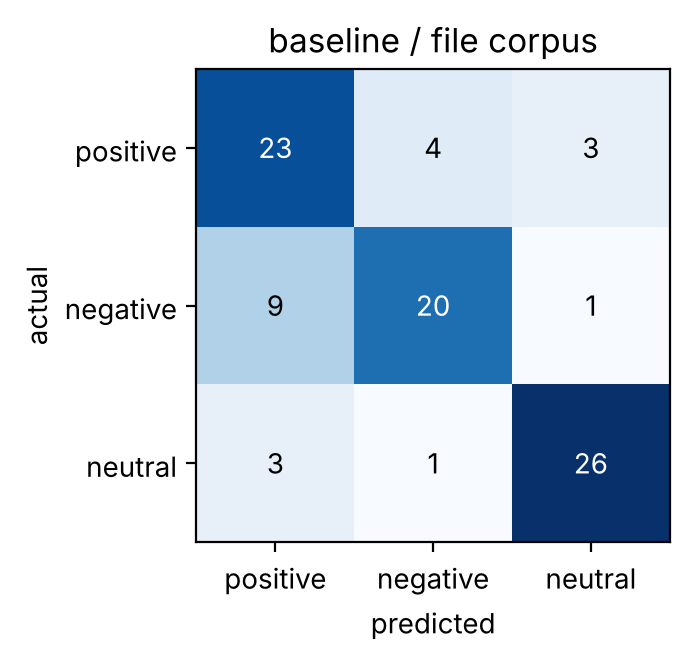

,text,label,pred
1,la livraison كانت سريعة و le livreur جد محترم,positive,negative
3,الدار الجديدة واسعة ومريحة، فرحانين بيها بزاف,positive,negative
7,j'adore ce téléphone، البطارية تقعد نهار كامل,positive,neutral
11,ربي يخليك خويا، ساعدتني بزاف,positive,negative
18,الجامعة نظمو يوم دراسي مفيد بزاف,positive,neutral
24,حبيت بزاف الهدية، شكرا من القلب,positive,negative
25,rani contant bzaf bel résultat ta3 l'examen,positive,neutral
32,"wallah l'connexion mchi mliha, kol nhar tweqef",negative,positive
35,rani t3ban bzaf mel khedma w l'stress,negative,positive
36,الأستاذ ما يجاوبش على الأسئلة والدرس ما فهمتوش,negative,positive


In [9]:
show_confusion(result["on_generated"], f"baseline / {GEN_MODE} corpus",
               RESULTS_DIR / f"confusion_{TASK}_{GEN_MODE}_baseline.png")   # draws and saves the matrix
get_errors(predicted, 10)[["text", "label", "pred"]]   # table of the first 10 errors (intended vs predicted)

## 8. Usefulness of the synthetic corpus — the key experiment
**Question**: does generating data with an LLM really help?

**Method**: we train the baseline classifier in 4 different ways and **always test it on the reference sentences** (the gold):

| Case | Training | Test |
|---|---|---|
| **A** | gold only (3/4 of the gold) | remaining 1/4 of the gold (cross-validation) |
| **B** | **template** corpus (offline) only | the whole gold |
| **C** | corpus **written by the LLM** only | the whole gold |
| **D** | gold (3/4) **+** LLM corpus | remaining 1/4 of the gold (cross-validation) |

**How to read it**: if **C** is close to **A**, the synthetic corpus almost replaces human data. If **D** > **A**, it usefully completes it (*data augmentation*). If **B** is poor, a repetitive corpus teaches nothing useful about the real language.

,case,accuracy,macro F1
0,A · gold only (cross-validation),0.3542,0.3509
1,B · template corpus only → gold,0.6875,0.6824
2,C · LLM corpus only → gold,0.8542,0.8540
3,D · gold + LLM corpus (cross-validation),0.7917,0.7942


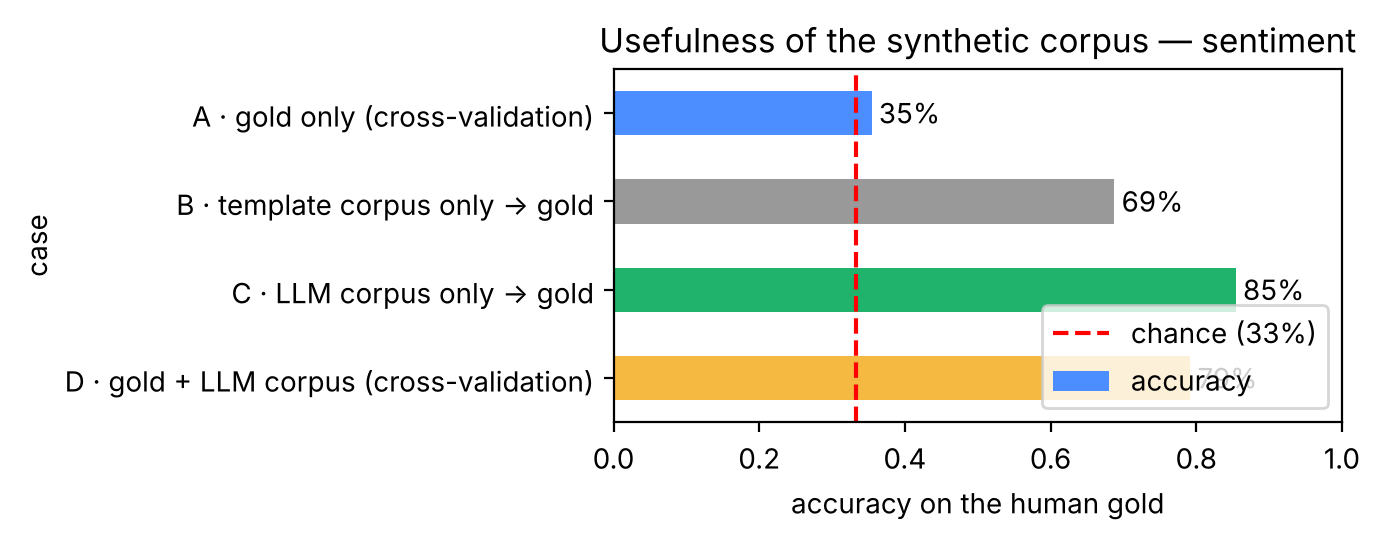

In [10]:
def utility_experiment(task):                       # runs the 4 cases A, B, C, D for one task
    gold_df = gold_dataframe(task)                  # the gold (test set of B and C)
    offline_corpus = generate_offline(task, N_PER_LABEL, RANDOM_SEED)   # template corpus
    file_corpus = load_corpus_file(task)            # corpus written by an LLM
    setups = {}                                     # results: case -> (name, true labels, predictions)

    true_a, pred_a = cv_gold(task)                  # A: gold only, cross-validation
    setups["A"] = ("A · gold only (cross-validation)", true_a, pred_a)

    model_b = make_baseline().fit(offline_corpus["text"], offline_corpus["label"])   # B: trained on the templates...
    setups["B"] = ("B · template corpus only → gold", list(gold_df["label"]), list(model_b.predict(gold_df["text"])))   # ...tested on the gold

    model_c = make_baseline().fit(file_corpus["text"], file_corpus["label"])         # C: trained on the LLM corpus...
    setups["C"] = ("C · LLM corpus only → gold", list(gold_df["label"]), list(model_c.predict(gold_df["text"])))   # ...tested on the gold

    true_d, pred_d = cv_gold(task, extra=file_corpus)   # D: gold + LLM corpus, cross-validation
    setups["D"] = ("D · gold + LLM corpus (cross-validation)", true_d, pred_d)

    rows, saved = [], {}                            # display table; data saved for the presentation
    for key, (name, y_true, y_pred) in setups.items():   # for each case
        m = evaluate(y_true, y_pred, task)          # accuracy, F1, ...
        rows.append({"case": name, "accuracy": m["accuracy"], "macro F1": m["macro_f1"]})   # table row
        saved[key] = {"label": name, "accuracy": m["accuracy"], "macro_f1": m["macro_f1"]}   # saved version
    (RESULTS_DIR / f"utility_{task}.json").write_text(json.dumps(saved, ensure_ascii=False, indent=2), encoding="utf-8")   # used by section 11
    return pd.DataFrame(rows), setups


def plot_utility(table, task):                      # bar chart of the 4 cases
    chance = 1 / len(LABELS[task])                  # chance level: 1 / number of classes
    ax = table.set_index("case")["accuracy"].plot.barh(figsize=(7, 2.8), xlim=(0, 1), color=["#4c8dff", "#999999", "#1fb36b", "#f5b942"])   # horizontal bars
    ax.axvline(chance, color="red", linestyle="--", label=f"chance ({chance:.0%})")   # red line = chance level
    for bar in ax.patches:                          # writes the value at the end of each bar
        ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height() / 2, f"{bar.get_width():.0%}", va="center")
    ax.invert_yaxis()                               # A at the top, D at the bottom
    ax.set_xlabel("accuracy on the human gold")     # axis label
    ax.legend(loc="lower right")                    # legend of the red line
    plt.title(f"Usefulness of the synthetic corpus — {task}")   # title
    plt.tight_layout()                              # margins
    plt.show()                                      # display


table_sent, setups_sent = utility_experiment("sentiment")   # runs the experiment for sentiment
display(table_sent)                                 # shows the table
plot_utility(table_sent, "sentiment")               # shows the chart

## 9. The same thing for disinformation (fake / real)

on the LLM corpus: accuracy=0.98  F1=0.98
on the human gold: accuracy=0.55  F1=0.5489


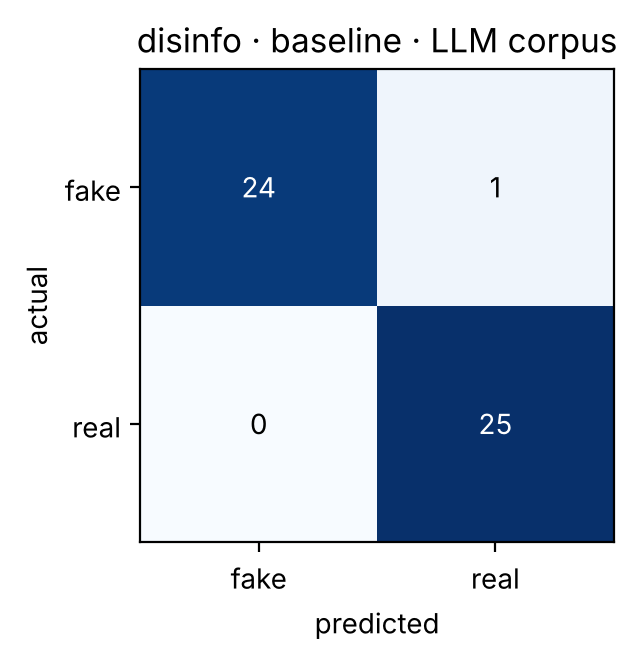

,case,accuracy,macro F1
0,A · gold only (cross-validation),0.55,0.5489
1,B · template corpus only → gold,1.00,1.0000
2,C · LLM corpus only → gold,0.95,0.9499
3,D · gold + LLM corpus (cross-validation),0.95,0.9499


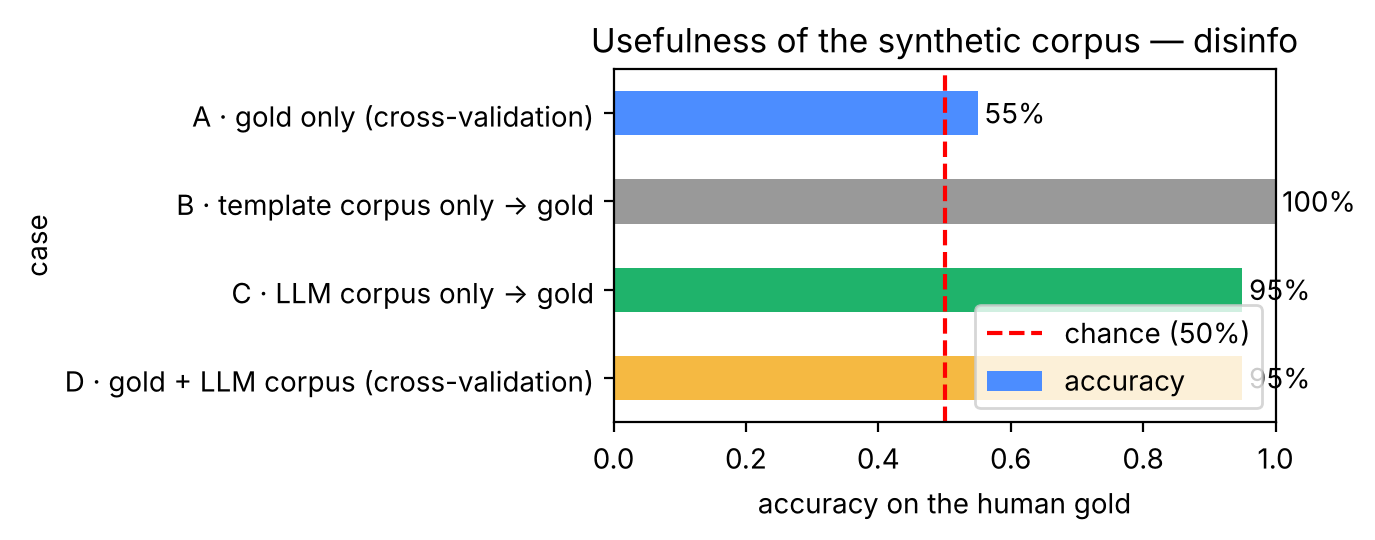

,text,label,pred
10,URGENT!! l'université t7ebs l'cours l'année ka...,fake,real


In [11]:
disinfo_corpus = generate("disinfo", "file")        # fake / real corpus written by an LLM
disinfo_pred, disinfo_res = evaluate_classifier(disinfo_corpus, "disinfo", "file")   # evaluates the baseline (saving included)
print(f"on the LLM corpus: accuracy={disinfo_res['on_generated']['accuracy']}  F1={disinfo_res['on_generated']['macro_f1']}")   # score 1
print(f"on the human gold: accuracy={disinfo_res['on_gold']['accuracy']}  F1={disinfo_res['on_gold']['macro_f1']}")           # score 2
show_confusion(disinfo_res["on_generated"], "disinfo · baseline · LLM corpus")   # confusion matrix
table_dis, setups_dis = utility_experiment("disinfo")   # usefulness experiment A/B/C/D
display(table_dis)                                  # table
plot_utility(table_dis, "disinfo")                  # chart
get_errors(disinfo_pred, 8)[["text", "label", "pred"]]   # a few errors to analyse

## 10. Try your own sentence
Edit `my_text`, choose the task, then run the cell. The baseline classifier is trained on the **gold + the LLM corpus** (the best case of section 8).

In [12]:
my_text = "wallah had l'application mli7a bzaf"      # your sentence (Darija, arabizi, or French / Arabic mix)
my_task = "sentiment"                               # "sentiment" or "disinfo"
train_all = pd.concat([gold_dataframe(my_task), generate(my_task, "file")])[["text", "label"]]   # gold + LLM corpus
my_model = make_baseline().fit(train_all["text"], train_all["label"])   # trains the baseline on everything
proba = my_model.predict_proba([my_text])[0]        # probability of each class
print(f"« {my_text} »  →  {my_model.predict([my_text])[0]}")   # predicted class
print({c: f"{p:.0%}" for c, p in zip(my_model.classes_, proba)})   # model confidence per class

« wallah had l'application mli7a bzaf »  →  positive
{'negative': '20%', 'neutral': '7%', 'positive': '73%'}


## 11. Update the presentation (`presentation/index.html`)
Writes the numbers of the 4 experiments (sections 8 and 9) into the animated bars of the presentation.

In [13]:
html_path = BASE_DIR / "presentation" / "index.html"   # path of the presentation
if not html_path.exists():                          # if the file is missing
    print("presentation/index.html not found: run the notebook from the project folder.")   # message
else:                                               # otherwise we update it
    html = html_path.read_text(encoding="utf-8")    # reads the whole HTML file into a string
    for task in ["sentiment", "disinfo"]:           # for each task
        saved = json.loads((RESULTS_DIR / f"utility_{task}.json").read_text(encoding="utf-8"))   # results of section 8/9
        for key, info in saved.items():             # for each case A, B, C, D
            value = f"{info['accuracy'] * 100:.1f}" # accuracy as a percentage
            html = re.sub(rf'(id="u-{task}-{key}" data-v=")[^"]*(")', rf"\g<1>{value}\g<2>", html)   # replaces data-v="..." of this bar
            print(f"u-{task}-{key}: {value} %")     # shows what was written
    html_path.write_text(html, encoding="utf-8")    # rewrites the presentation
    print("presentation/index.html updated ✅")

u-sentiment-A: 35.4 %
u-sentiment-B: 68.8 %
u-sentiment-C: 85.4 %
u-sentiment-D: 79.2 %
u-disinfo-A: 55.0 %
u-disinfo-B: 100.0 %
u-disinfo-C: 95.0 %
u-disinfo-D: 95.0 %
presentation/index.html updated ✅


## 12. Glossary & limits
| Word | Simple explanation |
|---|---|
| **Darija** | Algerian dialectal Arabic |
| **Arabizi** | Darija written with Latin letters + digits (`3`=ع, `7`=ح, `9`=ق, `5`=خ) |
| **Code-switching** | Mixing languages inside the same sentence (Arabic + French) |
| **NLG / NLU** | Text generation / text understanding |
| **LLM** | Large language model (ChatGPT, Claude, Llama...) |
| **Prompt** | The text sent to the LLM |
| **Few-shot** | Giving a few examples in the prompt to guide the LLM |
| **Gold** | Reference data, labelled and reviewed by humans, assumed correct |
| **Synthetic corpus** | Data made by a model rather than collected in real life |
| **TF-IDF** | Turns text into numbers according to the importance of word pieces |
| **Character n-gram** | A piece of n consecutive letters (e.g. "mli" in "mli7a") |
| **Logistic regression** | A simple model that computes one probability per class |
| **Cross-validation** | Train on one part of the data and test on the rest, several times |
| **Accuracy** | Share of correct predictions |
| **Macro F1** | Average of the F1 of each class |
| **Confusion matrix** | Table actual × predicted |
| **Data augmentation** | Adding synthetic data to the training set |
| **Data leakage** | Testing a model on data it has already seen: falsely good score |

## Limits to mention in front of the jury
- The gold is **small** (48 sentences for sentiment, 20 for disinformation): the figures are indicative, with a large margin of uncertainty.
- The gold **and** the LLM corpus were written with the help of an LLM (same "hand"): the test is easier than with real Darija collected on social media. **Have the gold reviewed and corrected by native speakers.**
- The LLM corpus is **small** (90 + 50 sentences) and written in **a single session**: little diversity.
- The synthetic labels are the **intention** of the prompt, not a human annotation.
- In disinformation, the classifier learns the **style** of fake news, not the truth of the facts.
- To go further: human annotation of a sample (inter-annotator agreement), more data, fine-tuning a model (DziriBERT, XLM-R), several generator LLMs, comparison with a pre-trained model or a few-shot LLM.